<a href="https://colab.research.google.com/github/simonpogo/AI/blob/main/Reinforcement_Learning_labirint.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Reinforcement Learning — Razlaga delovanja in navodila za študente

Ta zvezek prikazuje uporabo **metode okrepljenega učenja (Reinforcement Learning)** z algoritmom **Q-learning** za reševanje problema iskanja najkrajše poti skozi naključen labirint.

---

## 1. Kako deluje Q-learning v labirintu?

Agent (robot) nima vnaprejšnjih informacij ali znanja o tem, kje so zidovi ali kje je cilj. Uči se izključno s poskušanjem in napakami preko **interakcije z okoljem**.

### Ključni koncepti:
1. **Stanje ($S$):** Trenutna koordinata robota v labirintu, npr. $(r, c)$.
2. **Akcije ($A$):** Možne smeri premikanja: `LEVO`, `DESNO`, `GOR`, `DOL`.
3. **Nagrade ($R$):**
   * Dosežen cilj: $+150$ (spodbuja uspeh)
   * Trk v zid: $-5$ (hitro nauči agenta, kje so ovire)
   * Vsak korak: $-1$ (kazen za čas/energijo, spodbuja iskanje najkrajše poti)
4. **Q-tabela (Q-Table): 🧠 ** Možgani našega robota. To je matrika velikosti $20 \times 20 \times 4$, kjer vsaka celica hrani oceno kakovosti (Q-vrednost) za določeno akcijo v določenem stanju. Posodablja se po enačbi:

$$Q(s, a) \leftarrow Q(s, a) + \alpha \left( R + \gamma \max_{a'} Q(s', a') - Q(s, a) \right)$$

* **$\alpha$ (stopnja učenja - learning rate):** Določa, kako močno nova izkušnja vpliva na staro znanje.
* **$\gamma$ (diskontni faktor - discount factor):** Določa pomembnost prihodnjih nagrad v primerjavi s takojšnjimi.
* **Exploration vs. Exploitation (Raziskovanje proti izkoriščanju):** Nadzorovano s parametrom $\epsilon$ (epsilon). Na začetku robot večinoma raziskuje naključno ($\epsilon = 1.0$), z vsako epizodo pa $\epsilon$ upada (decay), dokler robot skoraj izključno ne uporablja pridobljenega znanja (pohlepna izbira).

##Kaj pomeni ALPHA - Stopnja učenja?
V našem programu parameter ALPHA (stopnja učenja ali learning rate) določa, kako hitro se agent (robot) uči iz novih izkušenj oziroma kolikšen vpliv ima nova informacija na že obstoječe znanje v Q-tabeli.

Če pogledamo enačbo za posodobitev Q-vrednosti v vaši kodi:

q_table[state][action_index] = old_value + ALPHA * (reward + GAMMA * next_max - old_value)
Lahko si jo predstavljate tudi tako: $$ Q_{novo} = (1 - \alpha) \cdot Q_{staro} + \alpha \cdot (\text{Nova izkušnja}) $$$$ Q_{novo} = (1 - \alpha) \cdot Q_{staro} + \alpha \cdot (\text{Nova izkušnja}) $$

Kaj pomenijo različne vrednosti za ALPHA ($\alpha$$\alpha$):
Nizka vrednost (npr. $\alpha = 0.1$$\alpha = 0.1$ - kot jo imate vi):

Agent se uči počasi in premišljeno.
Robot ne bo takoj spremenil svojega celotnega mnenja o nekem polju le na podlagi ene same dobre ali slabe izkušnje. Namesto tega bo postopoma gradil stabilne ocene.
To je zelo pomembno v okoljih z veliko naključnosti ali ko želimo stabilno konvergenco.
Visoka vrednost blizu $1.0$$1.0$ (npr. $\alpha = 0.9$$\alpha = 0.9$):

Agent se uči izjemno hitro in daje skoraj vso težo zadnji izkušnji.
Hitro bo pozabil stare ocene in jih nadomestil z najnovejšimi.
To lahko povzroči, da se robot v labirintu nenehno "premšlja" in težko stabilno konvergira k optimalni poti, saj lahko ena naključna napaka popolnoma uniči prejšnje učenje.
Mejna primera:

$\alpha = 0$$\alpha = 0$: Robot se sploh ne uči. Q-tabela ostane nespremenjena (vedno enaka začetnim vrednostim).
$\alpha = 1$$\alpha = 1$: Robot popolnoma ignorira pretekle izkušnje in upošteva samo najnovejšo dobljeno informacijo.





---

## 2. Kratka navodila za študente (Naloge za eksperimentiranje)

Za boljše razumevanje algoritma poskusite v zgornji kodi spremeniti naslednje parametre in opazujte rezultate:

1. **Vpliv gostote labirinta (`WALL_PROBABILITY`):**
   * Privzeto je delež zidov `0.28`. Povečajte ga na `0.35` ali zmanjšajte na `0.15`. Opazujte, kako se spreminja čas generiranja rešljivega labirinta in dolžina naučene poti.
2. **Hitrost upadanja raziskovanja (`EPSILON_DECAY`):**
   * Spremenite `EPSILON_DECAY` na `0.99` (hitrejše zmanjševanje). Ali se robot uspe naučiti najti cilj v manj epizodah ali pa konča v lokalnem optimumu (zanki)?
3. **Sprememba kazni za korak (`REWARD_STEP`):**
   * Če nastavite `REWARD_STEP = 0`, robot ne bo več kaznovan za dolge poti. Ali je končna naučena pot še vedno najkrajša možna?

Nov naključen labirint (20x20) ustvarjen.
Start (na robu): (0, 15) -> Cilj (na nasprotni strani): (19, 17)

Začenjam učenje robota z Q-learning algoritmom...

Epizoda  1000 | Povprečna nagrada: -863.02 | Epsilon: 0.606
Epizoda  2000 | Povprečna nagrada:   21.41 | Epsilon: 0.368
Epizoda  3000 | Povprečna nagrada:  107.61 | Epsilon: 0.223
Epizoda  4000 | Povprečna nagrada:  136.32 | Epsilon: 0.135
Epizoda  5000 | Povprečna nagrada:  149.75 | Epsilon: 0.082
Epizoda  6000 | Povprečna nagrada:  156.56 | Epsilon: 0.050
Epizoda  7000 | Povprečna nagrada:  160.71 | Epsilon: 0.030
Epizoda  8000 | Povprečna nagrada:  162.63 | Epsilon: 0.018
Epizoda  9000 | Povprečna nagrada:  164.04 | Epsilon: 0.011
Epizoda 10000 | Povprečna nagrada:  164.64 | Epsilon: 0.010
Epizoda 11000 | Povprečna nagrada:  164.35 | Epsilon: 0.010
Epizoda 12000 | Povprečna nagrada:  164.62 | Epsilon: 0.010

Učenje končano. Iščem najboljšo pot...
Robot je uspešno našel pot do cilja v 35 korakih!
Graf poti shranjen: /content/la

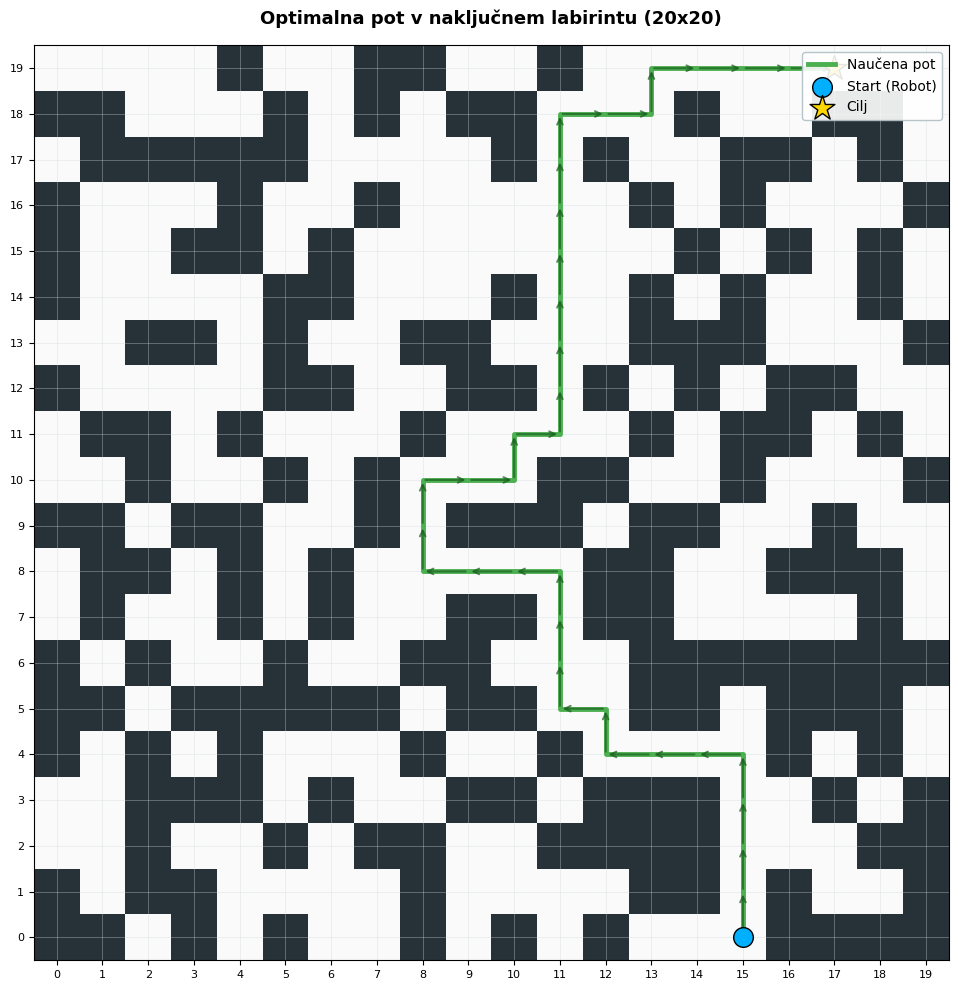

Graf nagrad shranjen: /content/labirint_nagrade.png


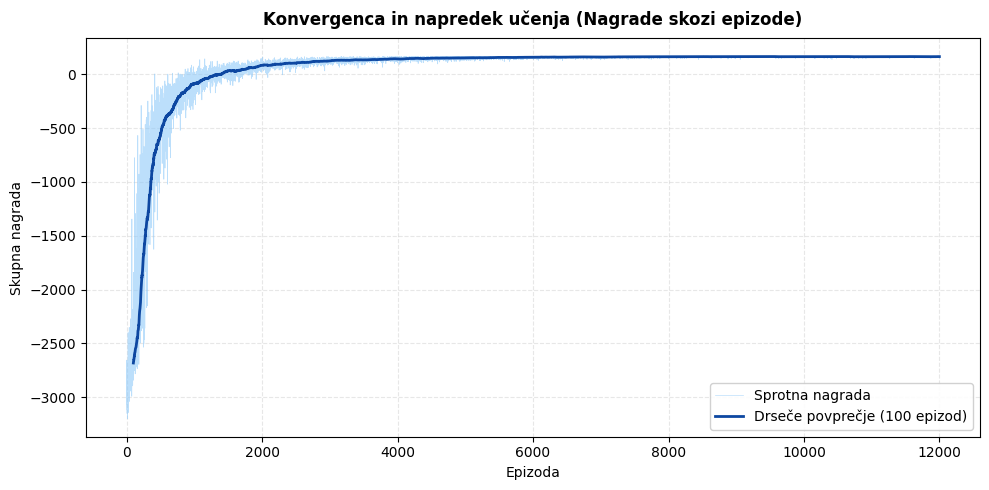

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import random

try:
    SCRIPT_DIR = os.path.dirname(os.path.abspath(__file__))
except NameError:
    SCRIPT_DIR = os.getcwd()

# ----------------------------------------------------------------------
# 1) GENERIRANJE NAKLJUČNEGA LABIRINTA IN NAKLJUČNIH TOČK
# ----------------------------------------------------------------------
MAZE_ROWS = 20
MAZE_COLS = 20
WALL_PROBABILITY = 0.50   # delež polj, ki bodo zidovi

# Štiri možne akcije: levo, desno, gor, dol
ACTIONS = [(0, -1), (0, 1), (-1, 0), (1, 0)]
ACTION_NAMES = ["LEVO", "DESNO", "GOR", "DOL"]

def is_valid(pos, maze):
    r, c = pos
    return 0 <= r < maze.shape[0] and 0 <= c < maze.shape[1] and maze[r, c] == 0

def has_path(maze, start, goal):
    """BFS: preveri, ali med start in goal sploh obstaja prehodna pot."""
    if maze[start] == 1 or maze[goal] == 1:
        return False

    from collections import deque
    visited = {start}
    queue = deque([start])

    while queue:
        current = queue.popleft()
        if current == goal:
            return True
        for move in ACTIONS:
            nxt = (current[0] + move[0], current[1] + move[1])
            if is_valid(nxt, maze) and nxt not in visited:
                visited.add(nxt)
                queue.append(nxt)
    return False

def choose_random_start_and_goal(rows, cols):
    """Naključno izbere start in goal na nasprotnih robovih (stranicah) labirinta."""
    # Izberemo par nasprotnih stranic: vodoravno (top-bottom) ali navpično (left-right)
    orientation = random.choice(["horizontal", "vertical"])

    if orientation == "horizontal":
        # Ena točka zgoraj, druga spodaj
        sides = [(0, random.randint(0, cols - 1)), (rows - 1, random.randint(0, cols - 1))]
        random.shuffle(sides)
        start, goal = sides[0], sides[1]
    else:
        # Ena točka levo, druga desno
        sides = [(random.randint(0, rows - 1), 0), (random.randint(0, rows - 1), cols - 1)]
        random.shuffle(sides)
        start, goal = sides[0], sides[1]

    return start, goal

def generate_random_maze(rows, cols, wall_probability=WALL_PROBABILITY, max_attempts=500):
    """Ustvari nov naključen labirint in določi prehodne start/goal točke na nasprotnih straneh."""
    for attempt in range(1, max_attempts + 1):
        start, goal = choose_random_start_and_goal(rows, cols)

        maze = (np.random.random((rows, cols)) < wall_probability).astype(int)
        maze[start] = 0
        maze[goal] = 0

        if has_path(maze, start, goal):
            print(f"Nov naključen labirint ({rows}x{cols}) ustvarjen.")
            print(f"Start (na robu): {start} -> Cilj (na nasprotni strani): {goal}")
            return maze, start, goal

    raise RuntimeError("Ni uspelo ustvariti rešljivega labirinta z nasprotnima točkama.")

# ----------------------------------------------------------------------
# 2) PARAMETRI UČENJA
# ----------------------------------------------------------------------
NUM_EPISODES = 12000     # Število epizod
MAX_STEPS = 600          # Krajša varovalka za hitrejše učenje
ALPHA = 0.1              # Stopnja učenja (learning rate)
GAMMA = 0.95             # Faktor prihodnjih nagrad
EPSILON_START = 1.0
EPSILON_MIN = 0.01
EPSILON_DECAY = 0.9995

REWARD_GOAL = 200        # Večja spodbuda za cilj
REWARD_WALL = -9         # Kazen za stene
REWARD_STEP = -1         # Spodbuda za najkrajšo pot

# ----------------------------------------------------------------------
# 3) POMOŽNE FUNKCIJE UČENJA
# ----------------------------------------------------------------------
def choose_action(state, q_table, epsilon):
    if random.random() < epsilon:
        return random.randint(0, len(ACTIONS) - 1)
    max_val = np.max(q_table[state])
    actions_with_max = np.flatnonzero(q_table[state] == max_val)
    return int(random.choice(actions_with_max))

def step(state, action_index, maze, goal):
    action = ACTIONS[action_index]
    next_state = (state[0] + action[0], state[1] + action[1])

    if not is_valid(next_state, maze):
        return state, REWARD_WALL, False
    if next_state == goal:
        return next_state, REWARD_GOAL, True
    return next_state, REWARD_STEP, False

# ----------------------------------------------------------------------
# 4) UČENJE (Q-LEARNING)
# ----------------------------------------------------------------------
def train(maze, start, goal, num_episodes=NUM_EPISODES):
    q_table = np.zeros(maze.shape + (len(ACTIONS),))
    epsilon = EPSILON_START
    rewards_per_episode = []
    steps_per_episode = []

    for episode in range(num_episodes):
        state = start
        total_reward = 0
        steps = 0
        done = False

        while not done and steps < MAX_STEPS:
            action_index = choose_action(state, q_table, epsilon)
            next_state, reward, done = step(state, action_index, maze, goal)

            # Q-learning posodobitev
            old_value = q_table[state][action_index]
            next_max = np.max(q_table[next_state])
            q_table[state][action_index] = old_value + ALPHA * (
                reward + GAMMA * next_max - old_value
            )

            state = next_state
            total_reward += reward
            steps += 1

        epsilon = max(EPSILON_MIN, epsilon * EPSILON_DECAY)
        rewards_per_episode.append(total_reward)
        steps_per_episode.append(steps)

        if (episode + 1) % 1000 == 0:
            avg_reward = np.mean(rewards_per_episode[-1000:])
            print(f"Epizoda {episode + 1:5d} | Povprečna nagrada: {avg_reward:7.2f} | Epsilon: {epsilon:.3f}")

    return q_table, rewards_per_episode, steps_per_episode

# ----------------------------------------------------------------------
# 5) IZLUŠČITEV NAJBOLJŠE POTI
# ----------------------------------------------------------------------
def get_optimal_path(q_table, start, goal, maze, max_steps=200):
    path = [start]
    state = start
    visited = {start}

    for _ in range(max_steps):
        if state == goal:
            break

        best_action = None
        best_value = -float("inf")

        for idx, move in enumerate(ACTIONS):
            next_state = (state[0] + move[0], state[1] + move[1])
            if is_valid(next_state, maze):
                val = q_table[state][idx]
                if next_state not in visited:
                    val += 1000
                if val > best_value:
                    best_value = val
                    best_action = idx

        if best_action is None:
            print("Robot je zašel v slepo ulico.")
            break

        move = ACTIONS[best_action]
        state = (state[0] + move[0], state[1] + move[1])
        path.append(state)
        visited.add(state)

    return path

# ----------------------------------------------------------------------
# 6) VIZUALIZACIJA
# ----------------------------------------------------------------------
def plot_maze_with_path(maze, path, start, goal):
    cmap = ListedColormap(["#fafafa", "#263238"])

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(maze, cmap=cmap)

    rows, cols = zip(*path)
    ax.plot(cols, rows, color="#4CAF50", linewidth=3.5, label="Naučena pot", zorder=3)

    for i in range(len(path) - 1):
        curr = path[i]
        nxt = path[i+1]
        ax.annotate('', xy=(nxt[1], nxt[0]), xytext=(curr[1], curr[0]),
                    arrowprops=dict(arrowstyle="->", color="#1b5e20", lw=1.5, alpha=0.7), zorder=4)

    ax.scatter(start[1], start[0], marker="o", color="#00B0FF",
                edgecolors="black", s=200, label="Start (Robot)", zorder=5)
    ax.scatter(goal[1], goal[0], marker="*", color="#FFD700",
                edgecolors="black", s=350, label="Cilj", zorder=5)

    ax.set_title(f"Optimalna pot v naključnem labirintu ({maze.shape[0]}x{maze.shape[1]})", fontsize=13, fontweight='bold', pad=15)
    ax.invert_yaxis()
    ax.set_xticks(range(0, maze.shape[1], 1))
    ax.set_yticks(range(0, maze.shape[0], 1))
    ax.tick_params(labelsize=8)
    ax.grid(True, which='both', color='#cfd8dc', linestyle='-', linewidth=0.5, alpha=0.5)
    ax.legend(loc="upper right", framealpha=0.9, facecolor='white', edgecolor='#b0bec5', fontsize=10)
    plt.tight_layout()

    output_path = os.path.join(SCRIPT_DIR, "labirint_pot.png")
    plt.savefig(output_path, dpi=150)
    print(f"Graf poti shranjen: {output_path}")
    plt.show()
    plt.close()

def plot_rewards(rewards):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(rewards, linewidth=0.5, color="#90caf9", alpha=0.6, label="Sprotna nagrada")

    window = 100
    if len(rewards) >= window:
        moving_avg = np.convolve(rewards, np.ones(window)/window, mode='valid')
        ax.plot(range(window-1, len(rewards)), moving_avg, linewidth=2, color="#0d47a1", label=f"Drseče povprečje ({window} epizod)")

    ax.set_title("Konvergenca in napredek učenja (Nagrade skozi epizode)", fontsize=12, fontweight='bold', pad=10)
    ax.set_xlabel("Epizoda", fontsize=10)
    ax.set_ylabel("Skupna nagrada", fontsize=10)
    ax.grid(True, alpha=0.3, linestyle='--')
    ax.legend(loc="lower right", framealpha=0.9, facecolor='white')
    plt.tight_layout()

    output_path = os.path.join(SCRIPT_DIR, "labirint_nagrade.png")
    plt.savefig(output_path, dpi=150)
    print(f"Graf nagrad shranjen: {output_path}")
    plt.show()
    plt.close()

# ----------------------------------------------------------------------
# 7) GLAVNI PROGRAM
# ----------------------------------------------------------------------
if __name__ == "__main__":
    random.seed(None)
    np.random.seed(None)

    # Ustvarimo labirint z naključnimi točkami na nasprotnih robovih
    MAZE, START, GOAL = generate_random_maze(MAZE_ROWS, MAZE_COLS)

    print("\nZačenjam učenje robota z Q-learning algoritmom...\n")
    Q, rewards, steps = train(MAZE, START, GOAL)

    print("\nUčenje končano. Iščem najboljšo pot...")
    optimal_path = get_optimal_path(Q, START, GOAL, MAZE)

    if optimal_path[-1] == GOAL:
        print(f"Robot je uspešno našel pot do cilja v {len(optimal_path) - 1} korakih!")
    else:
        print("Robot ni uspel priti do cilja s čisto pohlepno izbiro.")

    plot_maze_with_path(MAZE, optimal_path, START, GOAL)
    plot_rewards(rewards)